# Geometric Morphometrics of Pistillate Flowers in *Astrocaryum* sect. Huicungo (Arecaceae) — Reproduction of the Authors' R Pipeline

**Paper**: Meza, V., Moreno, G., Daza, M. & Millán, B. (2026). *Geometric Morphometrics of Pistillate Flowers in Astrocaryum sect. Huicungo (Arecaceae): Taxonomic Implications for the Peruvian Species.* bioRxiv preprint v1 (posted 2026-11-06), DOI: [10.64898/2026.11.04.764277](https://doi.org/10.64898/2026.11.04.764277) (CC BY 4.0).

**Data & code**: Zenodo deposit [DOI 10.5281/zenodo.21176287](https://doi.org/10.5281/zenodo.21176287) (record 21176287, CC BY 4.0) — `Astrocaryum_Morphometrics.R`, `p_calyx.TPS`, `p_corolla.TPS`.

**Purpose**: Reproduce the paper's complete geometric-morphometric analysis by running the **authors' own deposited R script, unmodified**, on the authors' deposited landmark data: Generalized Procrustes Analysis (GPA), bilateral object symmetry, hierarchical Procrustes ANOVA, PCA (95%-ellipse morphospace), Canonical Variate Analysis with leave-one-out cross-validation, Mahalanobis distances, and UPGMA dendrograms — for calyx, corolla, and the combined perianth.

**Scope & status**: Executed demonstration (partial scientific scope). The original microscopy images used for digitization are not in the Zenodo record, so this notebook starts from the deposited 2D landmark coordinates (549 pistillate flowers, 11 Peruvian species, 20 points each: 4 fixed landmarks + 16 sliding semilandmarks). Running this pipeline does not re-verify the paper's dataset-level conclusions beyond what the deposited data support.

**How it runs**: This is a Python notebook only in the sense that short Python cells **launch** the authors' R code with `Rscript`; every scientific operation is the authors' R implementation (geomorph 4.0.10, Morpho 2.12 — the versions stated in the paper). No AI re-implementation of the method is involved. One small supplementary cell (clearly labeled) recomputes cross-validated classification rates that the authors' script does not print, following the authors' exact function calls.

**日本語要約**: このノートブックは、論文著者自身が Zenodo に公開した R 解析スクリプト(`Astrocaryum_Morphometrics.R`)を**一切変更せずに** Colab 上で実行し、カリックス(花萼)・コロラ(花冠)・両者結合のランドマークデータ(549 花、11 種、20 点)について GPA・左右対称成分抽出・Procrustes ANOVA・PCA・CVA(交差検証)・マハラノビス距離・UPGMA 樹形図を再現します。Python のセルは R の起動役だけです。計測に使った顕微鏡画像は Zenodo に含まれないため、再現は公開済みランドマーク座標から始まります。

## 1. Runtime selection

**Select: `Runtime` → `Change runtime type` → `CPU` (standard). No GPU is needed** — the analysis is multivariate statistics on 549 × 20 landmark coordinates; the authors' script contains no GPU code path.

Expected timing (measured on a standard Colab CPU runtime, 2026-11-26): R package install ≈ 30–35 min (source builds, streamed), remaining cells ≈ 5–10 min, total ≈ 40–45 min. Downloads ≈ 0.5 MB.

**Run all**: `Runtime` → `Run all`. Every cell must succeed; failures stop with explicit errors.

**日本語**: ランタイムは「CPU」を選択してください(GPU 不要)。全体の目安は 10–20 分、ダウンロードは約 0.5 MB です。「ランタイム → すべてのセルを実行」で実行できます。

In [ ]:
import os, shutil, subprocess, platform

# Work in /content (all downloads and analysis stay on this Colab VM)
os.chdir("/content")

# The scientific code is the authors' R script, so R must be present.
# Standard Colab CPU/GPU images ship with R; fail explicitly otherwise.
rscript = shutil.which("Rscript")
if rscript is None:
    raise RuntimeError(
        "Rscript was not found on this runtime. Use a standard Colab runtime "
        "image (which includes R), or install R via 'apt-get install r-base'."
    )

ver = subprocess.run(["Rscript", "-e", "cat(R.version.string)"],
                     capture_output=True, text=True, timeout=120, check=True)
print("R       :", ver.stdout.strip())
print("Python  :", platform.python_version())
print("Host    :", platform.machine(), "| CPUs:", os.cpu_count())

R       : R version 4.6.1 (2026-06-24)
Python  : 3.13.18
Host    : x86_64 | CPUs: 2


## 2. R environment setup

The paper states the analysis was run with **R 4.4.3, geomorph 4.0.10 and Morpho 2.12** (Methods 4.3). This notebook installs the packages in two phases (validated 2026-11-26 on a Colab CPU runtime with R 4.6.1):

1. **Compiled spatial dependencies of Morpho** (`sf`, `s2`, `classInt`, `e1071`, `proxy`) from a *current* Posit Package Manager snapshot for Ubuntu jammy — the 2025-03-01 snapshot serves these only as source, and its old `s2` 1.1.7 does not compile with GCC 13. These are infrastructure for Morpho's file I/O, not used by the scientific pipeline.
2. **The paper's exact versions** — geomorph **4.0.10**, Morpho **2.12**, RRPP 2.1.2 (CRAN-current on 2025-03-01, verified via crandb) — from the dated snapshot `https://packagemanager.posit.co/cran/__linux__/jammy/2025-03-01`.

geomorph 4.0.10 requires R ≥ 4.4.0; the cell fails explicitly if the runtime's R is older. **Measured install time on a fresh standard CPU runtime (2 vCPU, 2026-11-26): ≈ 30–35 minutes** — everything compiles from source (RcppArmadillo, s2, sf, Morpho…), so this is the longest cell; its streamed output stays visible throughout. The remaining cells take ≈ 5–10 minutes together.

**日本語**: 論文が明記する geomorph 4.0.10 / Morpho 2.12 を 2025-03-01 時点のパッケージスナップショットから導入します。Morpho の依存ライブラリ(sf 系)は最新スナップショットから導入します(GCC 13 で古い s2 がビルドできないため)。新規ランタイムでは全パッケージがソースビルドのため、このセルだけで約 30–35 分かかります(進行状況は随時表示)。

In [ ]:
from pathlib import Path
import time

install_r = r'''

options(Ncpus = 4, timeout = 600)

if (getRversion() < "4.4.0")
  stop("geomorph 4.0.10 requires R >= 4.4.0; this runtime has ", R.version.string)

# Phase 1: compiled spatial dependencies of Morpho (sf -> s2/classInt/e1071/proxy).
# The 2025-03-01 snapshot serves these only as source, and the old s2 1.1.7
# fails to compile with GCC 13 (observed 2026-11-26 on Colab R 4.6.1), so take
# them from a current snapshot instead. They are infrastructure for Morpho's
# file I/O and are not used by the scientific pipeline below.
options(repos = c(P3M = "https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20"))
install.packages(c("proxy", "e1071", "classInt", "s2", "sf"))

# Phase 2: the paper's exact package versions (Methods 4.3: geomorph 4.0.10,
# Morpho 2.12) from the dated snapshot; RRPP 2.1.2 was CRAN-current then.
options(repos = c(P3M = "https://packagemanager.posit.co/cran/__linux__/jammy/2025-03-01"))
install.packages(c("geomorph", "Morpho", "RRPP"))

cat("\n--- installed versions ---\n")
for (p in c("geomorph", "Morpho", "RRPP", "ggplot2", "dplyr"))
  cat(sprintf("%-9s %s\n", p, as.character(packageVersion(p))))
'''
Path("/content/install_pkgs.R").write_text(install_r)

# Run R with line-streamed output: prints stay visible while installing AND are
# captured as persistent cell output (inherited streams are not captured by Colab).
proc = subprocess.Popen(["Rscript", "/content/install_pkgs.R"],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
start = time.time()
for line in proc.stdout:
    print(line, end="")
    if time.time() - start > 3000:
        proc.kill()
        raise RuntimeError("R package install exceeded 3000 s")
proc.wait()
if proc.returncode != 0:
    raise RuntimeError(f"R package install failed with exit code {proc.returncode}")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


also installing the dependencies ‘wk’, ‘units’

trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/wk_0.9.5.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/units_1.0-1.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/proxy_0.4-29.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/e1071_1.7-17.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/classInt_0.4-11.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/s2_1.1.13.tar.gz'
trying URL 'https://packagemanager.posit.co/cran/__linux__/jammy/2026-11-20/src/contrib/sf_1.1-3.tar.gz'


begin installing package ‘wk’
begin installing package ‘units’
begin installing package ‘proxy’


* installing *source* package ‘proxy’ ...
** this is package ‘proxy’ version ‘0.4-29’
** package ‘proxy’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/Rtmp7lO5hh/R.INSTALL1a5251fe7a78/proxy/src'
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c apply.c -o apply.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack

* installing *source* package ‘e1071’ ...
** this is package ‘e1071’ version ‘1.7-17’
** package ‘e1071’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
using C++ compiler: ‘x86_64-linux-gnu-g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/RtmpnS8RlK/R.INSTALL1ea64df82bb2/e1071/src'
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c Rsvm.c -o Rsvm.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffil

* installing *source* package ‘classInt’ ...
** this is package ‘classInt’ version ‘0.4-11’
** package ‘classInt’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
using Fortran compiler: ‘GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/RtmpV2sZeC/R.INSTALL1fb763217799/classInt/src'
x86_64-linux-gnu-gfortran  -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0  -c fish1.f -o fish1.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -W

... (15 outputs left out)

* installing *source* package ‘RRPP’ ...
** this is package ‘RRPP’ version ‘2.1.2’
** package ‘RRPP’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (RRPP)
begin installing package ‘geomorph’


* installing *source* package ‘geomorph’ ...
** this is package ‘geomorph’ version ‘4.0.10’
** package ‘geomorph’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (geomorph)


* installing *source* package ‘Rvcg’ ...
** this is package ‘Rvcg’ version ‘0.24’
** package ‘Rvcg’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
using C++ compiler: ‘x86_64-linux-gnu-g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/RtmpkpKSbG/R.INSTALL4a9c78df59f1/Rvcg/src'
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG -Ivcglib -I. -I'/usr/lib/R/site-library/Rcpp/include' -I'/usr/local/lib/R/site-library/RcppEigen/include' -I'/usr/local/lib/R/site-library/RcppArmadillo/include'     -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3   -c vcgl

* installing *source* package ‘Morpho’ ...
** this is package ‘Morpho’ version ‘2.12’
** package ‘Morpho’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
using C++ compiler: ‘x86_64-linux-gnu-g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/Rtmp2EX1RQ/R.INSTALL56353cf67692/Morpho/src'
x86_64-linux-gnu-g++ -std=gnu++20 -I"/usr/share/R/include" -DNDEBUG  -I'/usr/lib/R/site-library/Rcpp/include' -I'/usr/local/lib/R/site-library/RcppArmadillo/include'    -fopenmp -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3   -c CVAdists.cpp -o CVAdists.o
x86_64-linux-gnu-g++ -std

## 3. Acquire the pinned Zenodo deposit

Download the three files of Zenodo **version record 21176287** (DOI 10.5281/zenodo.21176287, CC BY 4.0) through its documented record API content links, and verify each file's byte size and MD5 against the record metadata (retrieved 2026-11-26):

| file | bytes | md5 |
|---|---|---|
| `Astrocaryum_Morphometrics.R` | 9,625 | `b11f7d9dd935cecb76cf4f8a27b74748` |
| `p_calyx.TPS` | 262,033 | `eee2f05c667ccf1183052354945391fb` |
| `p_corolla.TPS` | 260,325 | `95484f57dfeac4ef03f356c8dd77edb4` |

Any mismatch aborts the run — the analysis must not proceed on altered inputs.

**日本語**: Zenodo レコード 21176287 から 3 ファイルを取得し、サイズと MD5 をレコードのメタデータと照合します。一致しない場合は処理を中断します。

In [ ]:
import hashlib, requests

RECORD = 21176287
EXPECTED = {
    "Astrocaryum_Morphometrics.R": (9625,   "b11f7d9dd935cecb76cf4f8a27b74748"),
    "p_calyx.TPS":                 (262033, "eee2f05c667ccf1183052354945391fb"),
    "p_corolla.TPS":               (260325, "95484f57dfeac4ef03f356c8dd77edb4"),
}

for name, (size, md5) in EXPECTED.items():
    url = f"https://zenodo.org/api/records/{RECORD}/files/{name}/content"
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    data = r.content
    got_md5 = hashlib.md5(data).hexdigest()
    if len(data) != size or got_md5 != md5:
        raise RuntimeError(f"{name}: verification failed "
                           f"({len(data)} B vs {size} B expected, md5 {got_md5} vs {md5})")
    Path(name).write_bytes(data)
    print(f"OK  {name:32s} {len(data):>7d} B  md5 {got_md5}")

print("\nAll three files verified against the Zenodo record metadata.")

OK  Astrocaryum_Morphometrics.R         9625 B  md5 b11f7d9dd935cecb76cf4f8a27b74748


OK  p_calyx.TPS                       262033 B  md5 eee2f05c667ccf1183052354945391fb


OK  p_corolla.TPS                     260325 B  md5 95484f57dfeac4ef03f356c8dd77edb4

All three files verified against the Zenodo record metadata.


## 4. Inspect the TPS landmark data

A `.TPS` file (tpsUtil/tpsDig2 format) stores one `LM=<n>` block of 2D coordinates per specimen plus metadata lines. The authors' script reads it with `readland.tps(file, specID = "ID")` and parses specimen IDs like `car01_a1_r1` (species code `_` individual `_` rachilla position `b/m/a`), so the files must carry `ID=` labels. This cell — one of the open questions in the automated pre-study — verifies the structure directly from the downloaded bytes: 549 specimens × 20 points, ID format, per-species and per-position counts.

**日本語**: TPS ファイルの実データを検査し、549 標本 × 20 点、`ID=` ラベルの形式(種コード・個体・花位置)を確認します。

In [ ]:
def parse_tps(path):
    specimens, cur = [], None
    for raw in open(path, encoding="utf-8", errors="replace"):
        parts = raw.strip().split()
        if not parts:
            continue
        key = parts[0].upper()
        if key.startswith("LM="):
            cur = {"n_lm": int(parts[0].split("=")[1]), "pts": [], "id": None}
            specimens.append(cur)
        elif key.startswith("ID="):
            if cur is not None:
                cur["id"] = raw.strip()[3:].strip()
        elif cur is not None and len(parts) == 2:
            try:
                cur["pts"].append((float(parts[0]), float(parts[1])))
            except ValueError:
                pass
    return specimens

for struct in ["p_calyx.TPS", "p_corolla.TPS"]:
    spec = parse_tps(struct)
    n_pts = {len(s["pts"]) for s in spec}
    n_lm  = {s["n_lm"] for s in spec}
    no_id = [i for i, s in enumerate(spec) if not s["id"]]
    if not (len(spec) == 549 and n_pts == {20} and n_lm == {20} and not no_id):
        raise RuntimeError(f"{struct}: unexpected structure "
                           f"(specimens={len(spec)}, points={n_pts}, LM={n_lm}, missing IDs={len(no_id)})")
    ids = [s["id"] for s in spec]
    from collections import Counter
    sp = Counter(i[:3] for i in ids)
    pos = Counter(i[6] for i in ids)
    print(f"{struct}: 549 specimens x 20 points, all ID-labelled")
    print("  first IDs:", ids[:3])
    print("  species codes:", dict(sorted(sp.items())))
    print("  rachilla position (b=basal, m=medial, a=apical):", dict(sorted(pos.items())))
    print()

p_calyx.TPS: 549 specimens x 20 points, all ID-labelled
  first IDs: ['car01_a1_r1', 'car01_a2_r1', 'car01_a3_r1']
  species codes: {'car': 45, 'cho': 54, 'far': 90, 'gra': 54, 'hui': 36, 'jav': 27, 'mac': 54, 'per': 81, 'sco': 63, 'ule': 27, 'uro': 18}
  rachilla position (b=basal, m=medial, a=apical): {'a': 183, 'b': 183, 'm': 183}

p_corolla.TPS: 549 specimens x 20 points, all ID-labelled
  first IDs: ['car01_a1_r1', 'car01_a2_r1', 'car01_a3_r1']
  species codes: {'car': 45, 'cho': 54, 'far': 90, 'gra': 54, 'hui': 36, 'jav': 27, 'mac': 54, 'per': 81, 'sco': 63, 'ule': 27, 'uro': 18}
  rachilla position (b=basal, m=medial, a=apical): {'a': 183, 'b': 183, 'm': 183}



## 5. Preview the raw digitized landmarks

Before the statistics, look at the actual input: raw (unaligned) 2D coordinates of two deposited specimens. Per the authors' slider definition (`rbind(define.sliders(1:10), define.sliders(11:20))`, which in geomorph's AUTO mode anchors each chain at its endpoints), points **1, 10, 11, 20 are the 4 fixed landmarks** and points 2–9, 12–19 are the 16 sliding semilandmarks. This is a raw input view — no Procrustes alignment or sliding has been applied yet.

**日本語**: 解析前の生ランドマークを可視化します(青 = 固定ランドマーク 4 点、赤 = スライド式セミランドマーク 16 点)。まだ整位は行っていません。

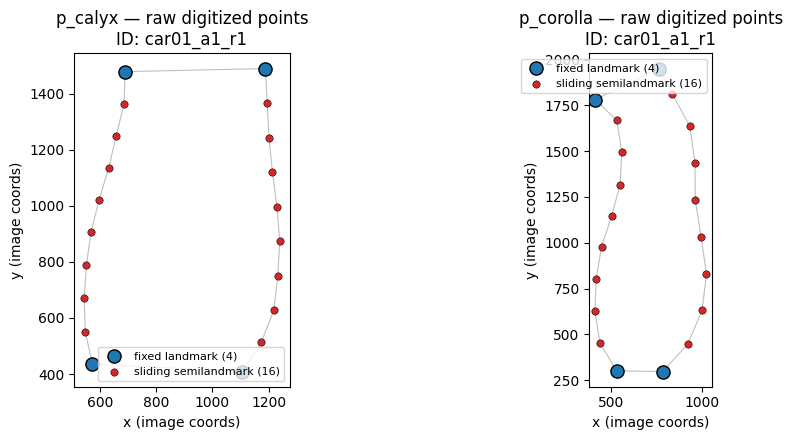

In [ ]:
import matplotlib.pyplot as plt

FIXED = [0, 9, 10, 19]          # 0-based indices of points 1, 10, 11, 20

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, fname in zip(axes, ["p_calyx.TPS", "p_corolla.TPS"]):
    spec = parse_tps(fname)[0]
    xs, ys = zip(*spec["pts"])
    ax.scatter([xs[i] for i in FIXED], [ys[i] for i in FIXED],
               c="tab:blue", s=90, edgecolor="k", zorder=3, label="fixed landmark (4)")
    semi = [i for i in range(20) if i not in FIXED]
    ax.scatter([xs[i] for i in semi], [ys[i] for i in semi],
               c="tab:red", s=28, edgecolor="k", linewidth=0.4, zorder=2,
               label="sliding semilandmark (16)")
    ax.plot(list(xs) + [xs[0]], list(ys) + [ys[0]], "-", color="0.75", lw=0.8, zorder=1)
    ax.set_title(f"{fname[:-4]} — raw digitized points\nID: {spec['id']}")
    ax.set_aspect("equal"); ax.legend(fontsize=8, loc="best")
    ax.set_xlabel("x (image coords)"); ax.set_ylabel("y (image coords)")
plt.tight_layout(); plt.show()

## 6. Run the authors' R pipeline (unmodified)

This cell executes `Astrocaryum_Morphometrics.R` **byte-for-byte unmodified** (MD5 verified above) with `Rscript`. The only wrapper is an R `png(...)` graphics device opened before `source()`, so every figure the script prints — the two ggplot PCA morphospace plots and the three base-R UPGMA dendrograms — is captured as a numbered PNG file (`fig_001.png` … `fig_005.png`) instead of going to a discarded `Rplots.pdf`. All console output (Procrustes ANOVA tables, Mahalanobis distance matrices) is streamed below.

Script sections executed: §2 data import → §3 bilateral symmetry (999 RRPP iterations) + GPA → §4 metadata from IDs → §5 hierarchical Procrustes ANOVA (`coords ~ species * position + individual`, seed 123) → §6 PCA → §7 CVA/Mahalanobis → §8 UPGMA dendrograms → §9 combined calyx+corolla analysis.

**日本語**: 著者の R スクリプトを**一切変更せず** `Rscript` で実行します。`png()` デバイスでスクリプトが出力する図 5 枚(PCA 2 枚・UPGMA 3 枚)を PNG として保存し、ANOVA 表やマハラノビス距離行列はコンソール出力として表示します。数分かかります。

In [ ]:
import glob, subprocess, time

runner = (
    "options(width = 220); "
    "png('fig_%03d.png', width = 1500, height = 1050, res = 140); "
    "source('Astrocaryum_Morphometrics.R', echo = FALSE); "
    "while (dev.cur() > 1) dev.off()"
)

# Line-streamed Popen: the authors' console output (ANOVA tables, Mahalanobis
# matrices) is printed live AND kept as persistent cell output.
proc = subprocess.Popen(["Rscript", "-e", runner],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
start = time.time()
for line in proc.stdout:
    print(line, end="")
    if time.time() - start > 3600:
        proc.kill()
        raise RuntimeError("authors' pipeline exceeded 3600 s")
proc.wait()
if proc.returncode != 0:
    raise RuntimeError(f"authors' pipeline failed with exit code {proc.returncode}")

figs = sorted(glob.glob("fig_*.png"))
if len(figs) != 5:
    raise RuntimeError(f"expected 5 figures (2 PCA + 3 UPGMA), got {len(figs)}: {figs}")
print("\nSaved figures:", figs)

Loading required package: RRPP


Loading required package: rgl
This build of rgl does not include OpenGL functions.  Use
 rglwidget() to display results, e.g. via options(rgl.printRglwidget = TRUE).
Loading required package: Matrix



Attaching package: ‘Morpho’

The following object is masked from ‘package:RRPP’:

    classify


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




No curves detected; all points appear to be fixed landmarks.



No curves detected; all points appear to be fixed landmarks.

Sample Calyx: 549 flowers | Sample Corolla: 549 flowers


This is not an error!  It is a friendly warning.
 
Because variables in the linear model are redundant, 
the linear model design has been truncated (via QR decomposition). 
Original X columns: 93 
Final X columns (rank): 83 
Check coefficients or degrees of freedom in ANOVA to see changes.
 
Use suppressWarnings() to turn off these warnings. 




... (4 outputs left out)


================ MAHALANOBIS DISTANCES: CALYX ================
                 A. carnosum A. faranae A. huicungo A. javarense A. scopatum A. perangustatum A. macrocalyx A. gratum A. urostachys A. chonta
A. faranae          1.150763                                                                                                                 
A. huicungo         1.192831   1.238283                                                                                                      
A. javarense        1.562594   1.408435    1.775568                                                                                          
A. scopatum         2.945081   2.889941    2.725939     3.289747                                                                             
A. perangustatum    1.368448   1.482913    1.499824     1.684592    2.823768                                                                 
A. macrocalyx       2.988996   2.902422    2.446400     3.244610    2.566704        

singular Covariance matrix: General inverse is used. Threshold for zero eigenvalue is 1e-10 



================ MAHALANOBIS DISTANCES: CALYX + COROLLA ================
                 A. carnosum A. faranae A. huicungo A. javarense A. scopatum A. perangustatum A. macrocalyx A. gratum A. urostachys A. chonta
A. faranae          1.712324                                                                                                                 
A. huicungo         2.050639   1.841540                                                                                                      
A. javarense        2.317742   2.677806    2.738712                                                                                          
A. scopatum         3.568347   3.575563    3.210878     4.196995                                                                             
A. perangustatum    4.198036   4.634936    4.560049     5.026938    5.215403                                                                 
A. macrocalyx       3.804982   3.447836    2.990236     4.740237    3.1655


Saved figures: ['fig_001.png', 'fig_002.png', 'fig_003.png', 'fig_004.png', 'fig_005.png']


## 7. PCA morphospace (authors' figures, verbatim outputs)

`fig_001.png` and `fig_004.png` are the PCA scatter plots with 95%-confidence ellipses exactly as printed by the authors' script (`plot_pca_calyx` and `plot_pca_combined`, script §6 and §9). The paper reports PC1+PC2 capturing 94.41% (calyx) and 85.65% (combined) of variance; compare the axis labels of these regenerated figures with those reported values.

**日本語**: 著者のスクリプトがそのまま出力した PCA 図(花萼・花萼+花冠結合)を表示します。軸ラベルの寄与率を論文値(花萼 94.41%、結合 85.65%)と比べてください。

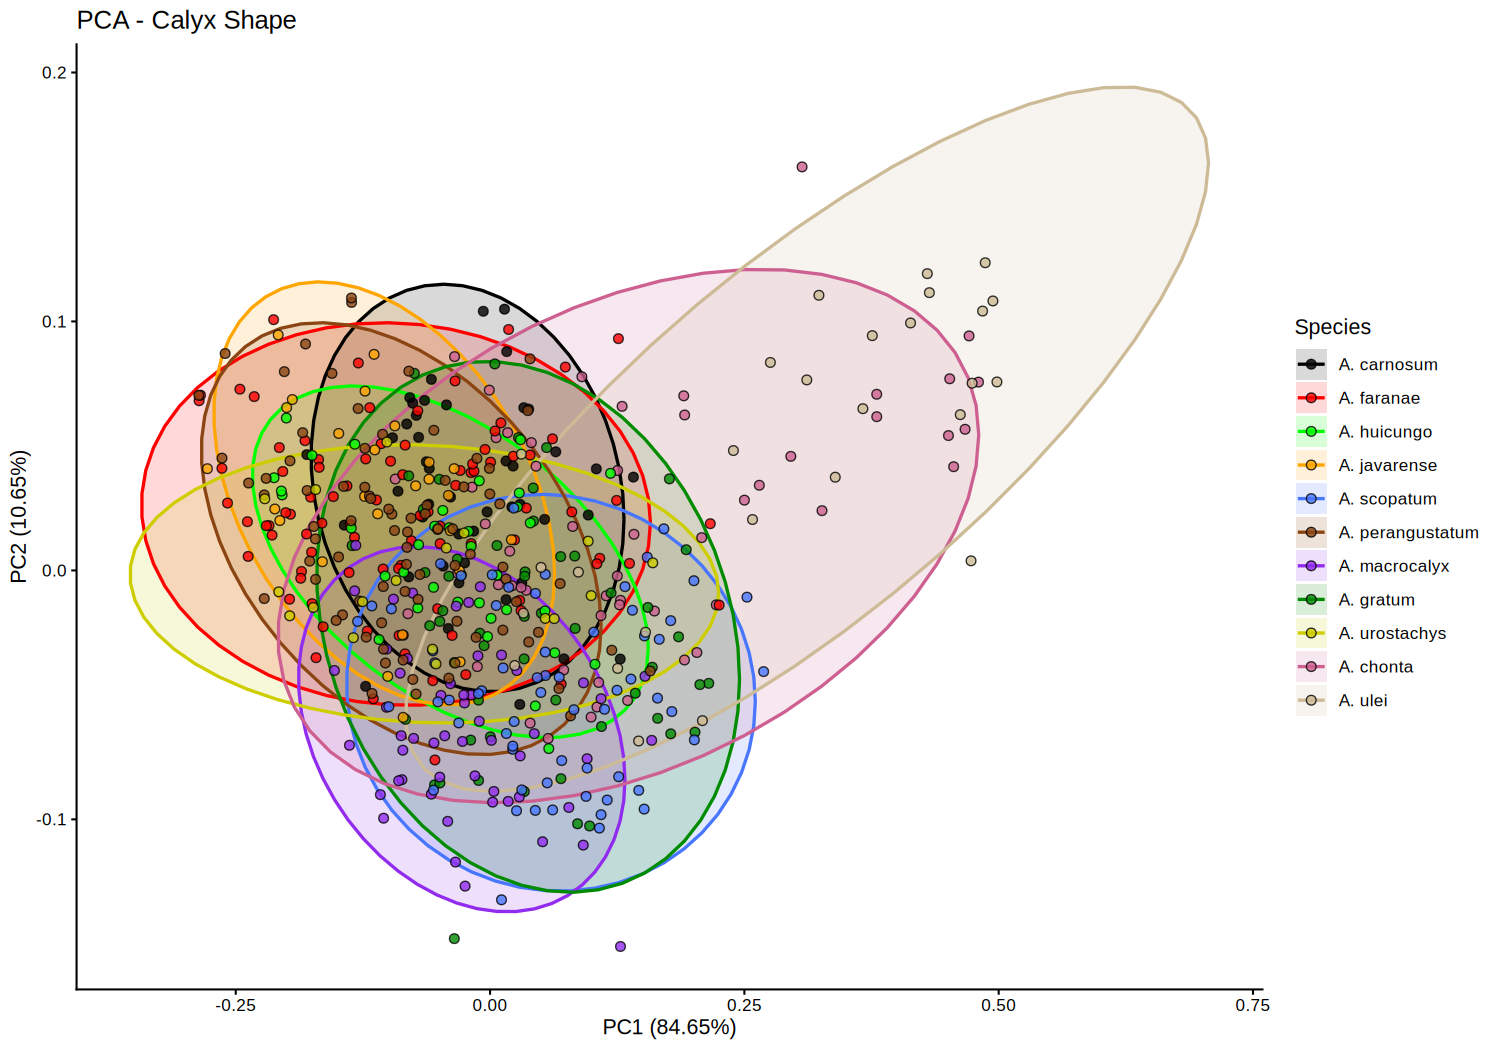

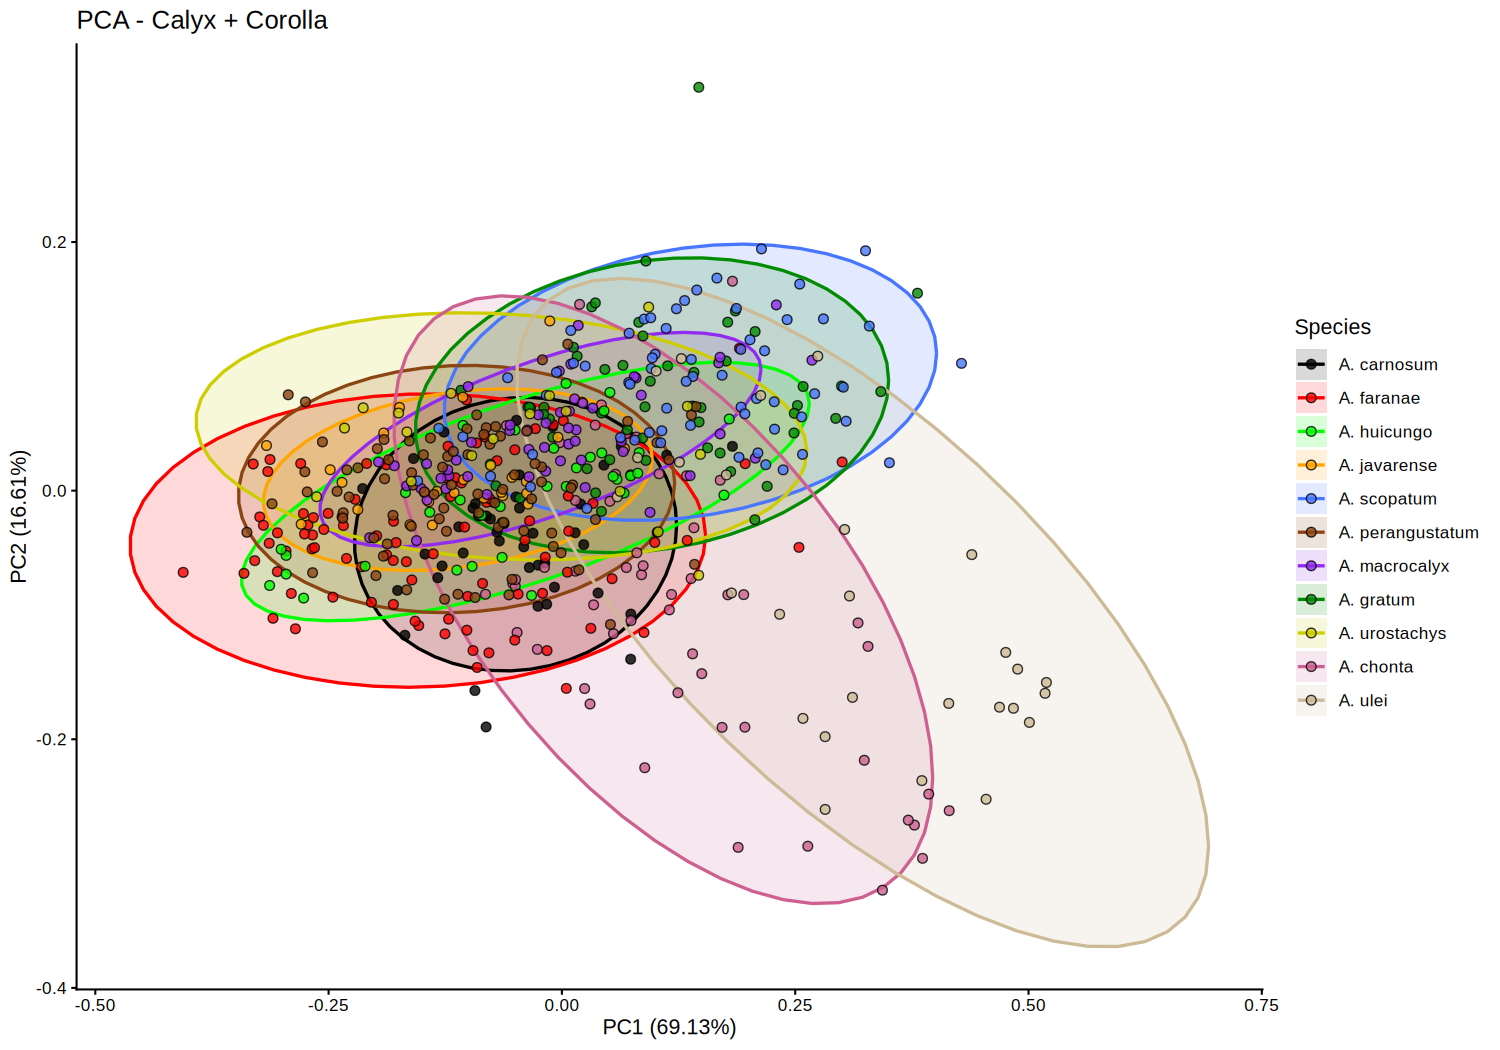

In [ ]:
from IPython.display import Image, display

figs = sorted(glob.glob("fig_*.png"))
# authors' print order: [0] PCA calyx, [1] UPGMA calyx, [2] UPGMA corolla,
#                       [3] PCA combined, [4] UPGMA combined
display(Image(figs[0], width=760))   # "PCA - Calyx Shape"
display(Image(figs[3], width=760))   # "PCA - Calyx + Corolla"

## 8. UPGMA phenetic dendrograms (authors' figures, verbatim outputs)

`fig_002.png`, `fig_003.png` and `fig_005.png` are the UPGMA dendrograms clustered from the Mahalanobis distance matrices among the 11 species mean shapes (script §8–§9, `hclust(method = "average")`). The paper interprets these against Kahn's traditional subsections (Huicungo, Sachacungo, Murumuru) and reports that the subsections are not replicated.

**日本語**: マハラノビス距離に基づく UPGMA 樹形図 3 枚(花萼・花冠・結合)を表示します。伝統的な亜節区分を反映しないクラスタリングが論文の主張です。

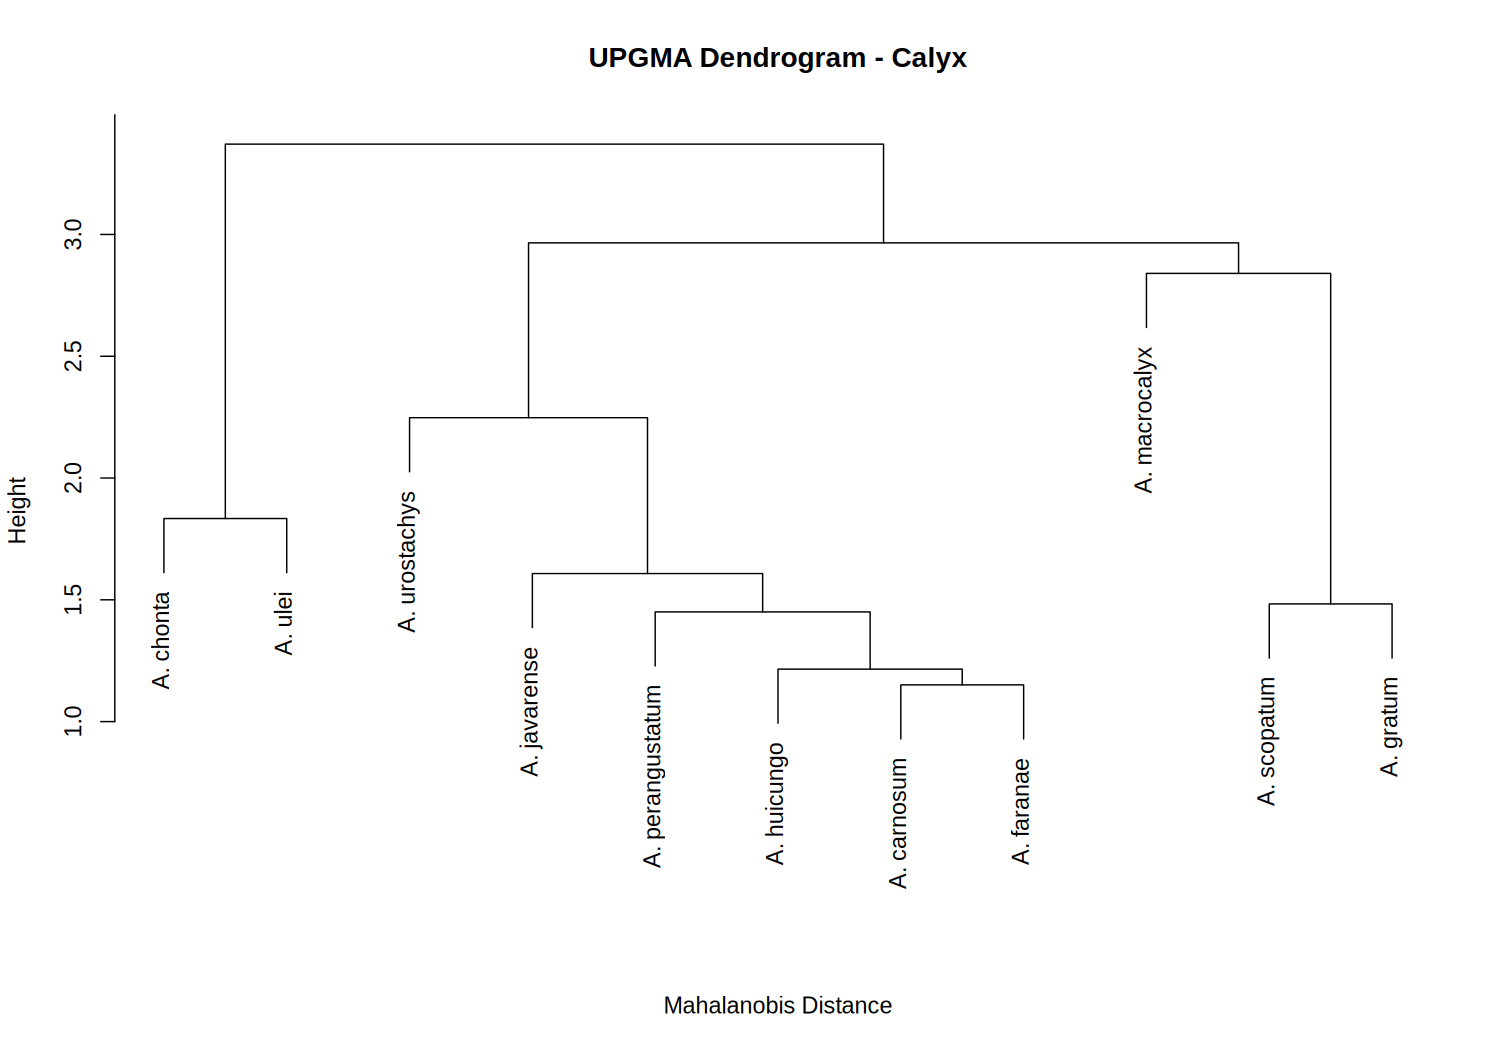

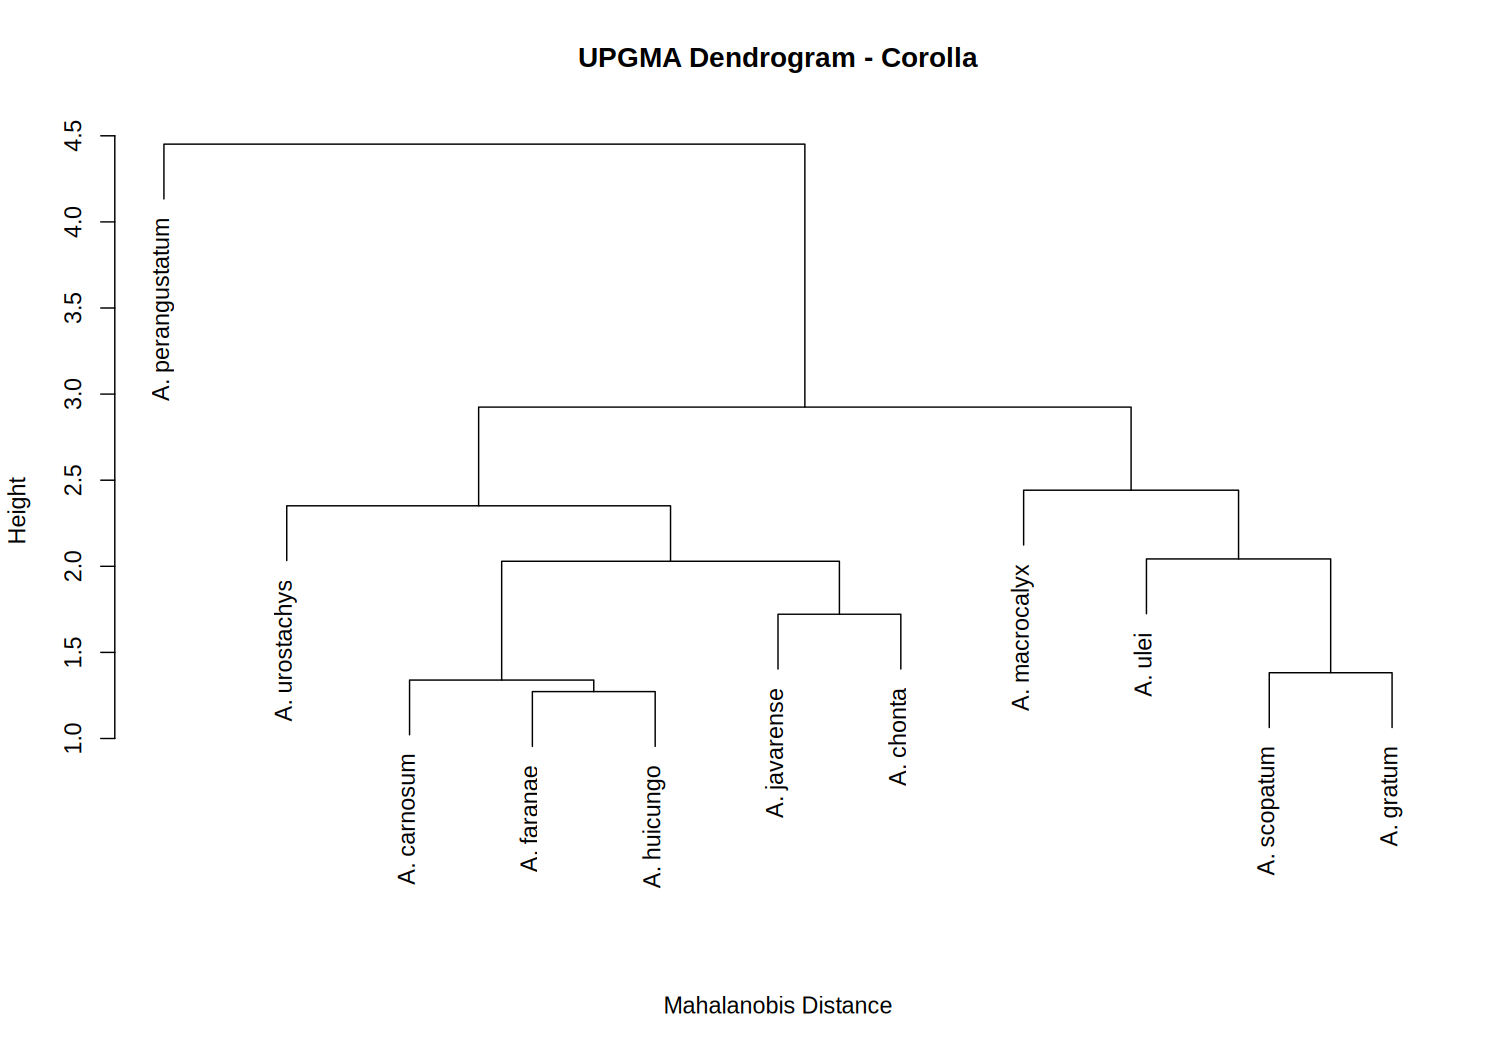

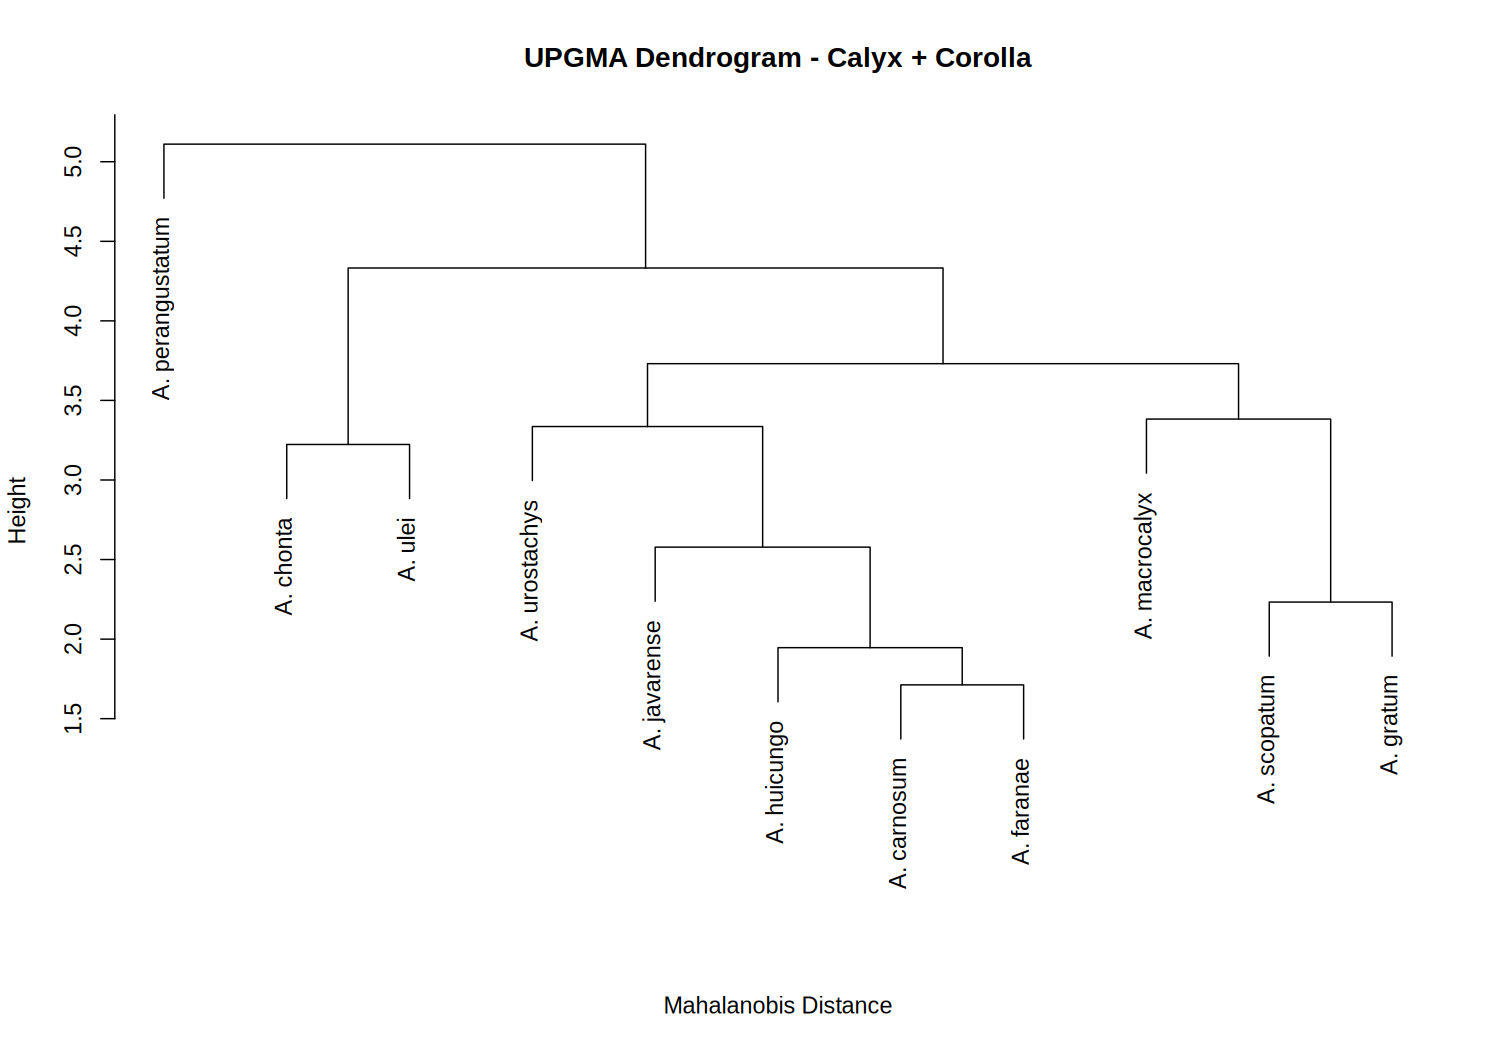

In [ ]:
figs = sorted(glob.glob("fig_*.png"))
display(Image(figs[1], width=760))   # "UPGMA Dendrogram - Calyx"
display(Image(figs[2], width=760))   # "UPGMA Dendrogram - Corolla"
display(Image(figs[4], width=760))   # "UPGMA Dendrogram - Calyx + Corolla"

## 9. Cross-validated classification rates (supplementary cell, notebook-added)

The authors' script runs `CVA(..., cv = TRUE)` (leave-one-out cross-validation) but only prints the Mahalanobis distance matrices — it never prints the cross-validated correct classification rates (CCR) that the paper reports (calyx **44.26%**, corolla **53.92%**, combined **64.85%**; Results 2.3).

The R script below is **AI-authored glue, not part of the authors' code**: it repeats the authors' exact preprocessing calls (`readland.tps` → `bilat.symmetry(object.sym=TRUE)` → symmetric component, script lines 41–74) and their exact CVA calls (`Morpho::CVA(groups, cv=TRUE, plot=FALSE)`, script lines 157–158 and 193; combined = `cbind(two.d.array calyx, two.d.array corolla)`, lines 183–185), then reports `mean(cva$class == groups)` per structure, using the documented Morpho 2.12 output field `class` (LOO-classified labels). It also exports the Mahalanobis distance matrices as CSV.

**日本語**: 著者スクリプトは CCR を印字しないため、**このノートブック追加分の補助セル**(AI 作成)で、著者と同一の前処理・CVA 呼び出しを用いて交差検証の正解分類率を計算し、論文値と比較します。

In [ ]:
from pathlib import Path

supp_r = r'''

# --- AI-authored supplementary script (NOT part of the authors' deposit) ---
# Recomputes the authors' deterministic preprocessing (Astrocaryum_Morphometrics.R
# lines 41-74) and their CVA calls (lines 157-158, 183-185, 193) to report the
# leave-one-out cross-validated classification rate (CCR) per structure.
library(geomorph); library(Morpho)

sliders <- rbind(define.sliders(1:10, write.file = FALSE),
                 define.sliders(11:20, write.file = FALSE))   # author line 47-49
pairs <- matrix(c(1,20, 2,19, 3,18, 4,17, 5,16,
                  6,15, 7,14, 8,13, 9,12, 10,11), ncol = 2, byrow = TRUE)  # author 52-55
lev  <- c("car","far","hui","jav","sco","per","mac","gra","uro","cho","ule")
labs <- c("A. carnosum","A. faranae","A. huicungo","A. javarense","A. scopatum",
          "A. perangustatum","A. macrocalyx","A. gratum","A. urostachys","A. chonta","A. ulei")

symm_shape <- function(file) {                    # author lines 41, 64-70, 73
  lmk  <- readland.tps(file, specID = "ID")
  symm <- bilat.symmetry(A = lmk, ind = dimnames(lmk)[[3]], land.pairs = pairs,
                         object.sym = TRUE, iter = 999, RRPP = TRUE,
                         print.progress = FALSE)
  symm$symm.shape
}

symm_calyx   <- symm_shape("p_calyx.TPS")    # returns the symmetric shape array
symm_corolla <- symm_shape("p_corolla.TPS")
ids    <- dimnames(symm_calyx)[[3]]                               # author line 79
groups <- factor(substr(ids, 1, 3), levels = lev, labels = labs)  # author 82-85

ccr <- function(coords, tag) {                    # author lines 157-158, 193
  cva <- CVA(coords, groups = groups, cv = TRUE, plot = FALSE)
  write.csv(round(cva$Dist$GroupdistMaha, 6), sprintf("mahalanobis_%s.csv", tag))
  rate <- 100 * mean(as.character(cva$class) == as.character(groups))
  cat(sprintf("CCR %-10s %6.2f%%\n", tag, rate))
  rate
}

ccr_calyx   <- ccr(symm_calyx,   "calyx")
ccr_corolla <- ccr(symm_corolla, "corolla")
combined <- cbind(two.d.array(symm_calyx),                        # author lines 183-185
                  two.d.array(symm_corolla))
ccr_combined <- ccr(combined, "combined")

ref <- data.frame(structure = c("calyx", "corolla", "combined"),
                  reproduced_ccr = round(c(ccr_calyx, ccr_corolla, ccr_combined), 2),
                  paper_reported_ccr = c(44.26, 53.92, 64.85))
write.csv(ref, "ccr_results.csv", row.names = FALSE)
cat("\n--- reproduced vs paper-reported CCR (%) ---\n")
print(ref, row.names = FALSE)
'''
Path("/content/supplementary_ccr.R").write_text(supp_r)
subprocess.run(["Rscript", "/content/supplementary_ccr.R"], check=True, timeout=3600)

CompletedProcess(args=['Rscript', '/content/supplementary_ccr.R'], returncode=0)

## 10. Results table and CSV export

Display the reproduced CCR summary next to the paper-reported values, and keep the CSVs produced on this VM (`ccr_results.csv`, `mahalanobis_*.csv`) available in the file browser for inspection. Agreement here is a consistency check of the deposited pipeline, not an independent validation of the paper's specimen sampling.

**日本語**: 再現した交差検証正解分類率(CCR)を論文報告値と並べて表示し、CSV として保存します。

In [ ]:
import pandas as pd

ref = pd.read_csv("ccr_results.csv")
print(ref.to_string(index=False))
ref.to_csv("astro_huicungo_ccr_summary.csv", index=False)
print("\nExported: astro_huicungo_ccr_summary.csv, mahalanobis_calyx.csv, "
      "mahalanobis_corolla.csv, mahalanobis_combined.csv")

structure  reproduced_ccr  paper_reported_ccr
    calyx           44.26               44.26
  corolla           53.92               53.92
 combined           64.85               64.85

Exported: astro_huicungo_ccr_summary.csv, mahalanobis_calyx.csv, mahalanobis_corolla.csv, mahalanobis_combined.csv


## 11. Interpretation, comparison with the paper, and limitations

**What this run shows** (see outputs above): the authors' deposited pipeline runs end-to-end on the deposited data and regenerates the paper's analyses — symmetry-partitioned GPA, hierarchical Procrustes ANOVA (species identity as the dominant variance source), PCA morphospace with 95% ellipses, LOO-cross-validated CVA classification, Mahalanobis distances, and UPGMA dendrograms for calyx, corolla and the combined perianth.

**Comparison with the paper** (bioRxiv v1, Results 2.1–2.3): reproduced quantities to check in the outputs — symmetric component share, species share of Procrustes-ANOVA variance (paper: 46.90% calyx / 44.00% corolla), PC1+PC2 variance (94.41% / 89.21% / 85.65%), and CCR (44.26% / 53.92% / 64.85%). The Procrustes ANOVA and CVA are deterministic given the data and the `set.seed(123)` / fixed iteration settings, so close agreement is expected; small differences can arise from package-version or platform differences.

**Limitations**: (i) this reproduces the *deposited analysis*, not the original digitization — the source microscope images and voucher/locality metadata are not in the Zenodo record; (ii) the deposited script uses 999-iteration RRPP and does not include the 10,000-iteration permutation test with Bonferroni correction described in the paper's Methods for Mahalanobis p-values, so those p-value tables are out of scope here; (iii) a single preprint version (v1) was used; (iv) results support the paper's qualitative claims on this dataset but are not an independent replication of the sampling.

**日本語**: 著者の解析パイプラインを公開データ上で末尾まで再実行し、論文の主要な統計量(対称成分の割合、種の分散寄与、PCA 寄与率、CCR)と比較できます。ただし(i)計測画像からのランドマーク化は再検証できず、(ii)スクリプトは論文本文の 10,000 回順列検定を含まない、(iii)プレプリント v1 の 1 バージョンに基づく、という限界があります。

## 12. Provenance and references

**Primary sources** (all verified 2026-11-26):
- Paper: bioRxiv preprint v1, DOI 10.64898/2026.11.04.764277 (CC BY 4.0) — https://doi.org/10.64898/2026.11.04.764277
- Code & data: Zenodo record 21176287, DOI 10.5281/zenodo.21176287 (CC BY 4.0); MD5s pinned in §3
- Author R script: `Astrocaryum_Morphometrics.R` (Meza, Moreno, Daza & Millán, 2026), executed unmodified
- R packages: geomorph 4.0.10 (GPL ≥ 3), Morpho 2.12 (GPL 2), RRPP 2.1.2, ggplot2, dplyr — Posit Package Manager snapshot 2025-03-01

**Notebook authorship**: orchestration cells (download/verification, Rscript launching, supplementary CCR cell, figure display) were written for this reproduction; the scientific computation is entirely the authors' R code. PhenoPaper automated study-flow records were used as research guidance only.

**References**: Adams, D.C. et al. *geomorph*; Schlager, S. *Morpho*; Collyer, M.L. & Adams, D.C. *RRPP*; Bookstein (1997) landmark methods; Klingenberg & McIntyre (1998) object symmetry; Kahn, F. (2008) *Astrocaryum* subsections.

**日本語**: 出典・ライセンスは上記の通り(CC BY 4.0)。科学計算はすべて著者提供の R コードであり、このノートブックの Python 部分は実行補助です。